# Import Modules

In [271]:
from dotenv import load_dotenv
load_dotenv()


import pymupdf
from langchain_community.document_loaders import PyMuPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
import easyocr, os

from langchain_chroma import Chroma
from langchain_huggingface import HuggingFaceEmbeddings

from langchain_openai import ChatOpenAI


import os
from langchain_openai import AzureChatOpenAI


from typing import TypedDict
from langgraph.graph import StateGraph, START, END

from langchain_core.messages import SystemMessage, HumanMessage
from langchain_core.prompts import ChatPromptTemplate

from redisvl.extensions.cache.llm import SemanticCache 
from redisvl.utils.vectorize import HFTextVectorizer
from urllib.parse import quote
import time
from langchain_openai import OpenAIEmbeddings







# Create the LLM


In [226]:

llm = AzureChatOpenAI(
    azure_deployment="gpt-4.1-mini",   # Azure mein tumne jo deployment name rakha hai
    azure_endpoint=os.getenv("AZURE_OPENAI_ENDPOINT"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY"),
    api_version="2024-12-01-preview",  # apne resource ke hisaab se check karo
    temperature=0,
)

# Read the PDF with Easy OCR

* Recognition: https://github.com/JaidedAI/EasyOCR/releases/download/v1.3/english_g2.zip
* Detector: https://github.com/JaidedAI/EasyOCR/releases/download/pre-v1.1.6/craft_mlt_25k.zip

In [4]:
data_path = r"C:\Users\csc\Desktop\Kuntal_work\PharmaStudyHelper\Data\NEJMoa1501352.pdf"
study_name=os.path.basename(data_path)
writing_path =r"C:\Users\csc\Desktop\Kuntal_work\PharmaStudyHelper\x_smantic_cache\data\my_data.txt"

In [228]:
# Easy OCR + Document
def DocumentExtraction(path):

    reader = easyocr.Reader(['en'], gpu=False)

    docs=[]
    pdf=pymupdf.open(data_path)
    for i, page in enumerate(pdf):
        img = page.get_pixmap(dpi=200).tobytes('png')
        text =" ".join(reader.readtext(img, detail=0))
        docs.append(Document(
            page_content=text, metadata={'page': i+1, 'study_name': study_name}
        ))
    return docs
docs=DocumentExtraction(path=data_path)


Using CPU. Note: This module is much faster with a GPU.
c:\Users\csc\Desktop\Kuntal_work\PharmaStudyHelper\pharmaEnv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


# Get the Mean of the each page words

In [ ]:

def MeanFinder(docs):
    import pandas as pd

    rows=[ 
        {"Page": i+1, "word_count":len(x.page_content.split())} for i, x in enumerate(docs)
        ]
    df=pd.DataFrame(rows)
    
    return int(df['word_count'].mean()//1)


In [ ]:
# Make the chunker
def Chunker(docs):

    chunker = RecursiveCharacterTextSplitter(chunk_size=3500, chunk_overlap=MeanFinder(docs=docs))
    return chunker.split_documents(docs)

# Make the Vectore Store

In [ ]:


db_path =r"C:\Users\csc\Desktop\Kuntal_work\PharmaStudyHelper\x_smantic_cache\db\chorma_db"

def embedding(db_path,chunks):
     embeddings = HuggingFaceEmbeddings(
                model_name="sentence-transformers/all-MiniLM-L6-v2"  # local, free
            )
     if os.path.exists(db_path):
        print("Vectore Storage present")
        vectorstore=Chroma(collection_name="pharma_studies", embedding_function=embeddings, persist_directory=db_path)
        return vectorstore
     else:
        print("Creating Vectore Store")

       

        vectorstore = Chroma.from_documents(
            documents=chunks,
            embedding=embeddings,
            collection_name="pharma_studies",
            persist_directory=db_path,  # disk par save hoga
        )

        # test
        results = vectorstore.similarity_search("sitagliptin cardiovascular outcomes", k=3)
        for r in results:
            print(r.metadata, r.page_content[:200], "\n")

        return vectorstore 
vectore_store=embedding(db_path,chunks=Chunker(docs))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Vectore Storage present


In [275]:


db_path =r"C:\Users\csc\Desktop\Kuntal_work\PharmaStudyHelper\x_smantic_cache\db_openai01\chorma_db"

def embedding(db_path,chunks):
     embeddings = OpenAIEmbeddings(
                model="text-embedding-3-small"  
            )
     if os.path.exists(db_path):
        print("Vectore Storage present")
        vectorstore=Chroma(collection_name="pharma_studies", embedding_function=embeddings, persist_directory=db_path)
        return vectorstore
     else:
        print("Creating Vectore Store")

       

        vectorstore = Chroma.from_documents(
            documents=chunks,
            embedding=embeddings,
            collection_name="pharma_studies",
            persist_directory=db_path,  # disk par save hoga
        )

        # test
        results = vectorstore.similarity_search("sitagliptin cardiovascular outcomes", k=3)
        for r in results:
            print(r.metadata, r.page_content[:200], "\n")

        return vectorstore 
vectore_store=embedding(db_path,chunks=Chunker(docs))

Creating Vectore Store
{'study_name': 'NEJMoa1501352.pdf', 'page': 8} SITAGLIPTIN AND CARDIOVASCULAR OUTCOMES IN TYPE 2 DIABETES Table 1. (Continued: ) Hazard Ratio Outcome Sitagliptin Placebo (95% CI) Value no. per 100 no. per 100 no. %) person-pr no. '%) person-pr Hos 

{'page': 4, 'study_name': 'NEJMoa1501352.pdf'} SITAGLIPTIN AND CARDIOVASCULAR OUTCOMES IN TYPE 2 DIABETES randomization of approximately 14,000 patients vascular   prevention medications   (Table   S1 in with a 6-year study period in total would y 

{'page': 6, 'study_name': 'NEJMoa1501352.pdf'} SITAGLIPTIN AND CARDIOVASCULAR OUTCOMES IN TYPE 2 DIABETES 8 7.5 Placebo ; 7.0 Sitagliptin J 12 24 36 48 Study Visit (mo) No: of Patients Sitagliptin 7325 6779 6485 6454 6110 3524 1434 Placebo 7331 67 



# Make the Retriver

In [153]:
def GetRetriver(vectore_store):
    return vectore_store.as_retriever(search_type='mmr', search_kwargs={'k': 5, "fetch_k": 20, "lambda_mult":0.5})
retriver=GetRetriver(vectore_store)

# Cache builder

In [ ]:


REDIS_URL= (
f"rediss://:{quote(os.environ['REDIS_KEY'])}"
f"@{os.environ['REDIS_HOST']}:10000"
)

cache=SemanticCache(
name = 'pahrma_cache',
redis_url=REDIS_URL, 
vectorizer=HFTextVectorizer(model="sentence-transformers/all-MiniLM-L6-v2"), 
distance_threshold=0.1,
ttl=3600
)

# counter 
import redis
r=redis.Redis.from_url(REDIS_URL, decode_responses=True)


# Graph Builder

In [ ]:
class RagState(TypedDict):
    question : str 
    context : str 
    answer : str
    cache_hit: bool 
    

# Tuning the thresold


 threshold  hit_rate_on_similar  false_hit_rate  precision
      0.02                 0.00            0.00       0.00
      0.04                 0.00            0.00       0.00
      0.06                 0.07            0.00       1.00
      0.08                 0.27            0.00       1.00
      0.10                 0.33            0.00       1.00
      0.12                 0.47            0.07       0.88
      0.14                 0.53            0.07       0.89
      0.16                 0.73            0.20       0.79
      0.18                 0.73            0.20       0.79
      0.20                 0.73            0.27       0.73
      0.22                 0.73            0.47       0.61
      0.24                 0.80            0.47       0.63
      0.26                 0.87            0.47       0.65
      0.28                 0.93            0.53       0.64
      0.30                 0.93            0.60       0.61
      0.32                 0.93            0.67       0.

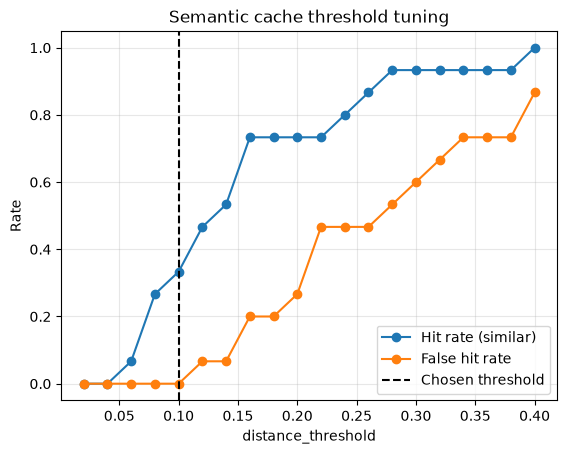

In [ ]:
import numpy as np
import pandas as pd

from redisvl.utils.vectorize import OpenAITextVectorizer



vectorizer = OpenAITextVectorizer(model="text-embedding-3-small")
# vectorizer = wahi jo SemanticCache mein use kar rahe ho
# label 1 = same intent (hit hona chahiye), 0 = alag intent (hit nahi hona chahiye)
pairs = [
    # ---- label 1: same intent, different wording (should HIT) ----
    ("What is the primary outcome of the TECOS study?", "What was the primary endpoint in TECOS?", 1),
    ("How many patients were enrolled in TECOS?", "What was the total number of participants in the TECOS trial?", 1),
    ("What are the side effects of sitagliptin?", "What adverse effects were reported with sitagliptin?", 1),
    ("What was the hazard ratio for the primary composite outcome?", "What hazard ratio was reported for the primary composite endpoint?", 1),
    ("Which year was the EMPA-REG OUTCOME study published?", "When was the EMPA-REG OUTCOME trial published?", 1),
    ("What drug was compared with placebo in TECOS?", "Which drug was tested against placebo in the TECOS trial?", 1),
    ("Did sitagliptin increase the risk of pancreatitis?", "Was there a higher risk of pancreatitis with sitagliptin?", 1),
    ("What was the follow-up duration of the study?", "How long were the patients followed up in the trial?", 1),
    ("What was the p-value for the primary outcome?", "What p-value was reported for the primary endpoint?", 1),
    ("What were the inclusion criteria of the trial?", "Which patients were eligible to be included in the trial?", 1),
    ("Which population was studied in the trial?", "What type of patients were included in the study?", 1),
    ("What was the rate of severe hypoglycemia?", "How often did severe hypoglycemia occur?", 1),
    ("What is the conclusion of the study?", "What did the authors conclude from the trial?", 1),
    ("What was the median age of participants?", "What was the average age of the patients in the study?", 1),
    ("Was the trial double blind?", "Was the study conducted as a double-blind trial?", 1),

    # ---- label 0: similar wording, different intent (should MISS) ----
    ("What is the primary outcome of TECOS?", "What is the primary outcome of EMPA-REG OUTCOME?", 0),
    ("What are the side effects of sitagliptin?", "What is the dose of sitagliptin?", 0),
    ("How many patients were enrolled in TECOS?", "How many patients died in TECOS?", 0),
    ("What was the hazard ratio for the primary outcome?", "What was the hazard ratio for heart failure hospitalization?", 0),
    ("What was the p-value for the primary outcome?", "What was the confidence interval for the primary outcome?", 0),
    ("What was the rate of severe hypoglycemia?", "What was the rate of acute pancreatitis?", 0),
    ("What were the inclusion criteria?", "What were the exclusion criteria?", 0),
    ("Which year was TECOS published?", "Which year did TECOS enrollment start?", 0),
    ("What is the primary outcome of the study?", "What is the secondary outcome of the study?", 0),
    ("What was the follow-up duration in TECOS?", "What was the dropout rate in TECOS?", 0),
    ("What is the mechanism of action of sitagliptin?", "What is the mechanism of action of empagliflozin?", 0),
    ("Did sitagliptin increase the risk of pancreatitis?", "Did sitagliptin increase the risk of cancer?", 0),
    ("What was the median age of participants?", "What was the median HbA1c at baseline?", 0),
    ("What is the conclusion of TECOS?", "What are the limitations of TECOS?", 0),
    ("Was the trial double blind?", "Was the trial funded by industry?", 0),
]

a = np.array(vectorizer.embed_many([p[0] for p in pairs]))
b = np.array(vectorizer.embed_many([p[1] for p in pairs]))
labels = np.array([p[2] for p in pairs])

cos_sim = (a * b).sum(1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1))
dist = 1 - cos_sim   # RedisVL cosine distance

rows = []
for t in np.arange(0.02, 0.41, 0.02):
    hit = dist <= t
    rows.append({
        "threshold": round(t, 2),
        "hit_rate_on_similar": hit[labels == 1].mean(),        # kitne paraphrase pakde
        "false_hit_rate": hit[labels == 0].mean(),             # galat hit (kam hona chahiye)
        "precision": (hit & (labels == 1)).sum() / max(hit.sum(), 1),
    })

df = pd.DataFrame(rows)
print(df.round(2).to_string(index=False))

safe = df[df["false_hit_rate"] == 0]
print("\nBest threshold (false hit 0, max hits):",
      safe.sort_values("threshold").iloc[-1]["threshold"] if len(safe) else "none, pairs ya model dekho")

safe_val=float(safe.sort_values("threshold").iloc[-1]["threshold"])


import matplotlib.pyplot as plt

plt.plot(df["threshold"], df["hit_rate_on_similar"], marker="o", label="Hit rate (similar)")
plt.plot(df["threshold"], df["false_hit_rate"], marker="o", label="False hit rate")
plt.axvline(safe_val, linestyle="--", color="black", label="Chosen threshold")
plt.xlabel("distance_threshold")
plt.ylabel("Rate")
plt.title("Semantic cache threshold tuning")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Done")



# Recrate the Cache

In [ ]:
cache=SemanticCache(
name = 'pahrma_cache',
redis_url=REDIS_URL, 
vectorizer=HFTextVectorizer(model="sentence-transformers/all-MiniLM-L6-v2"), 
distance_threshold=0.11, # chnage from 0.1 to 0.11
ttl=3600
)

# counter 
import redis
r=redis.Redis.from_url(REDIS_URL, decode_responses=True)


# Grpah Functions

In [265]:
def StringAggrigation(state: RagState):
    retriver=GetRetriver(vectore_store)
    retrived_docs=retriver.invoke(state['question'])
    text=[f"Metadata: {x.metadata} --> Page Content: {x.page_content}" for x in retrived_docs]
    return {"context": "\n\n".join(text)}



def Generation(state: RagState):
    prompt=ChatPromptTemplate.from_messages(
        [
            ("system", """You are a RAG LLM, see the question given by the user and give the answer from the given context only
                    if you dont find the answer in the context just say you don't know no assumtion
              
                CONTEXT:\n{context}
     """),
     
     ('human', "{question}")]
    )

  
        
    messages = prompt.invoke({"question": state['question'], "context": state['context']})
    return {"answer": llm.invoke(messages).content}



def CacheCheck(state: RagState):
    # checking the question if present in the cache
    q=state['question']
    r.zincrby("stats:asked", 1, q)
    hits = cache.check(prompt=state['question'], num_results=1)

    if hits:
        return {'answer': hits[0]['response'], 'cache_hit': True}
    return {'cache_hit': False}

# The cache routher
def route_after_cache(state: RagState):
    return 'hit' if state['cache_hit'] else 'miss'


def CacheStore(state: RagState):
    """If Cache does not contain the question then store the question and answer"""
    cache.store(prompt=state['question'], response=state['answer'])
    return {}





    


# Graph Building

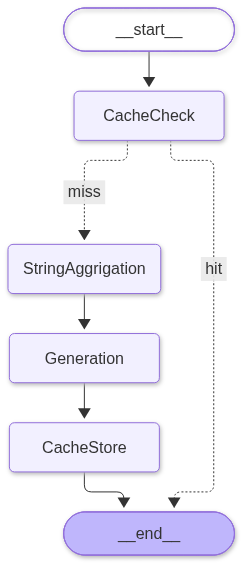

In [260]:

builder = StateGraph(RagState)
nodes = {
    "StringAggrigation": StringAggrigation,
    "Generation": Generation,
    "CacheCheck": CacheCheck,
    "CacheStore": CacheStore
}

for name,fn in nodes.items():
    builder.add_node(name,fn)

builder.add_edge(START, "CacheCheck")

builder.add_conditional_edges(
    "CacheCheck", route_after_cache, 
                    {'hit': END, 'miss':"StringAggrigation"}
)
builder.add_edge("StringAggrigation", "Generation")
builder.add_edge("Generation", "CacheStore")
builder.add_edge("CacheStore", END)
app=builder.compile()

app



# Check the Question if not chache 

In [261]:
input={"question":"What is the cvd outcome of tecos ?"}


start=time.perf_counter()
answer=app.invoke(input)
end=time.perf_counter()
print(f"Cahce Hit:{ answer['cache_hit']}")
print("*"*100)
print(f"Question: {answer['question']}")
print(f"Answer: {answer['answer']}")
print("*"*100)
non_cache = end-start
print(f"Time Taken: {round((end-start),4)} sec")


Cahce Hit:True
****************************************************************************************************
Question: What is the cvd outcome of tecos ?
Answer: The TECOS study found that among patients with type 2 diabetes and established cardiovascular disease, adding sitagliptin to usual care did not increase the risk of major adverse cardiovascular events. The hazard ratio for the primary composite cardiovascular outcome was 0.98 (95% CI, 0.88 to 1.09; P<0.001 for noninferiority), indicating no significant difference compared to placebo. Additionally, there was no significant difference in rates of hospitalization for heart failure (hazard ratio, 1.00; 95% CI, 0.83 to 1.20; P=0.98) or other adverse events such as acute pancreatitis or pancreatic cancer. Overall, sitagliptin did not increase cardiovascular risk in this patient population.
****************************************************************************************************
Time Taken: 3.5849 sec


# Check the Question if chache 

In [262]:
input={"question":"What is the cvd outcome of tecos ?"}


start=time.perf_counter()
answer=app.invoke(input)
end=time.perf_counter()
print(f"Cahce Hit:{ answer['cache_hit']}")
print("*"*100)
print(f"Question: {answer['question']}")
print(f"Answer: {answer['answer']}")
print("*"*100)
with_cache = end-start
print(f"Time Taken: {round((end-start),4)} sec")
print(f"Cache is fater than Non-Cache-->:{(non_cache/with_cache)//1}x")


Cahce Hit:True
****************************************************************************************************
Question: What is the cvd outcome of tecos ?
Answer: The TECOS study found that among patients with type 2 diabetes and established cardiovascular disease, adding sitagliptin to usual care did not increase the risk of major adverse cardiovascular events. The hazard ratio for the primary composite cardiovascular outcome was 0.98 (95% CI, 0.88 to 1.09; P<0.001 for noninferiority), indicating no significant difference compared to placebo. Additionally, there was no significant difference in rates of hospitalization for heart failure (hazard ratio, 1.00; 95% CI, 0.83 to 1.20; P=0.98) or other adverse events such as acute pancreatitis or pancreatic cancer. Overall, sitagliptin did not increase cardiovascular risk in this patient population.
****************************************************************************************************
Time Taken: 0.7225 sec
Cache is fater

# Most Asked Question

In [266]:
def show_stats(n=10):
    print("Most asked (exact text):")
    for q, c in r.zrevrange("stats:asked", 0, n - 1, withscores=True):
        print(f"  {int(c):>4}  {q}")
    print("Most cache hits (by cached question):")
    for q, c in r.zrevrange("stats:hits", 0, n - 1, withscores=True):
        print(f"  {int(c):>4}  {q}")

show_stats()

Most asked (exact text):
     2  What is the cvd outcome of tecos ?
Most cache hits (by cached question):


0.1